# Lab 05: Predict Late Deliveries

This notebook reads the results written by `python -m latedeliveries.train`. It does not refit the model or score the test set again, so the test set is still used only once.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from latedeliveries.data import make_orders
from latedeliveries.pipeline import (
    CATEGORY_FEATURES,
    EXCLUDED_COLUMNS,
    NUMERIC_FEATURES,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
orders = make_orders()

## How common are late orders?

In [2]:
counts = orders["late"].value_counts().sort_index()
print(counts.rename({0: "on time", 1: "late"}))
print(f"Late rate: {orders['late'].mean():.1%}")
print("Missing values:")
print(orders.isna().sum()[orders.isna().sum() > 0])

late
on time    2532
late        468
Name: count, dtype: int64
Late rate: 15.6%
Missing values:
prep_minutes        189
customer_rating    1489
dtype: int64


Roughly one order in six is late, so a model that always says on time already scores about 84% accuracy. Accuracy alone is not a useful measure here.

## Columns used

In [3]:
print("Numeric:", NUMERIC_FEATURES)
print("Category:", CATEGORY_FEATURES)
print("Excluded:", EXCLUDED_COLUMNS)

Numeric: ['distance_km', 'items', 'hour', 'prep_minutes', 'courier_months']
Category: ['weather', 'day_type', 'vehicle']
Excluded: ['order_id', 'customer_rating']


## Model comparison (5-fold stratified CV, training data only)

In [4]:
cv = pd.read_csv(REPORTS / "cv_results.csv")
cols = ["model"] + [c for c in cv.columns if c.endswith(("_mean", "_std"))]
cv[cols]

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,dummy_most_frequent,0.8440,0.0009,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000
1,logistic_regression,0.8622,0.0085,0.6541,0.0653,0.2420,0.0526,0.3516,0.0644,0.7951,0.0342
2,logistic_regression_balanced,0.7369,0.0187,0.3328,0.0267,0.6809,0.0493,0.4469,0.0337,0.7947,0.0338
3,random_forest_balanced,0.7871,0.0174,0.3816,0.0337,0.5839,0.0583,0.4609,0.0398,0.7824,0.0253
4,hist_gradient_boosting,0.8511,0.0060,0.5442,0.0364,0.2876,0.0374,0.3749,0.0357,0.7543,0.0236


In [5]:
cv[["model", "roc_auc_mean", "roc_auc_std", "lowest_cv_cost", "at_threshold"]]

,model,roc_auc_mean,roc_auc_std,lowest_cv_cost,at_threshold
0,dummy_most_frequent,0.5000,0.0000,5265,0.05
1,logistic_regression,0.7951,0.0342,4031,0.30
2,logistic_regression_balanced,0.7947,0.0338,4098,0.70
3,random_forest_balanced,0.7824,0.0253,4237,0.60
4,hist_gradient_boosting,0.7543,0.0236,4327,0.30


The cost column is the lowest out-of-fold cost each model reaches over the threshold grid on the 2,250 training orders. Flagging nobody costs $5,265 there.

## Leakage check: customer_rating added back

In [6]:
leak = pd.read_csv(REPORTS / "leakage_check.csv")
leak[["model", "roc_auc_mean", "roc_auc_std", "recall_mean", "f1_mean"]]

,model,roc_auc_mean,roc_auc_std,recall_mean,f1_mean
0,logistic_regression_with_rating,0.9073,0.0171,0.5384,0.6498


## Tuning and threshold

In [7]:
info = json.loads((ROOT / "models" / "model_info.json").read_text())
info["tuning"]

{'scoring': 'roc_auc',
 'best_params': {'model__C': 10.0, 'model__class_weight': None},
 'best_cv_roc_auc': 0.7952,
 'untuned_cv_roc_auc': 0.7951,
 'untuned_cv_roc_auc_std': 0.0342,
 'gain': 0.0001,
 'gain_beats_fold_spread': False}

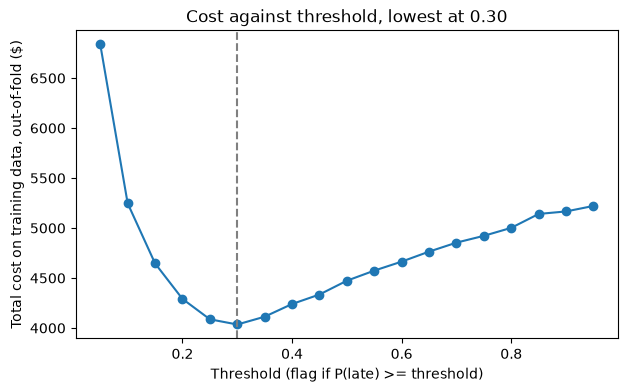

Chosen threshold: 0.3, out-of-fold cost $4035


In [8]:
costs = pd.read_csv(REPORTS / "threshold_costs.csv")
best = costs.loc[costs["cost"].idxmin()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(costs["threshold"], costs["cost"], marker="o")
ax.axvline(best["threshold"], linestyle="--", color="grey")
ax.set_xlabel("Threshold (flag if P(late) >= threshold)")
ax.set_ylabel("Total cost on training data, out-of-fold ($)")
ax.set_title(f"Cost against threshold, lowest at {best['threshold']:.2f}")
plt.show()
print(f"Chosen threshold: {info['threshold']}, out-of-fold cost ${int(best['cost'])}")

## Test set, scored once

In [9]:
metrics = json.loads((REPORTS / "metrics.json").read_text())
cm = metrics["confusion_matrix"]
matrix = pd.DataFrame(
    [
        [cm["true_negative"], cm["false_positive"]],
        [cm["false_negative"], cm["true_positive"]],
    ],
    index=["actual on time", "actual late"],
    columns=["not flagged", "flagged"],
)
print(matrix)
print({k: metrics[k] for k in ["precision", "recall", "f1", "roc_auc"]})

                not flagged  flagged
actual on time          578       55
actual late              64       53
{'precision': 0.4907, 'recall': 0.453, 'f1': 0.4711, 'roc_auc': 0.7962}


flag_nobody       1755
flag_everybody    3000
model             1392
Name: cost ($), dtype: int64


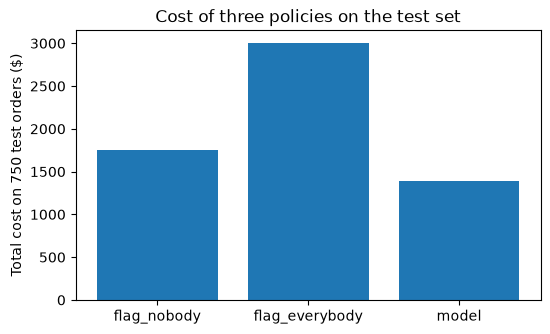

In [10]:
policies = pd.Series(metrics["policy_costs"], name="cost ($)")
print(policies)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(policies.index, policies.values)
ax.set_ylabel("Total cost on 750 test orders ($)")
ax.set_title("Cost of three policies on the test set")
plt.show()

## Recommendation

**Would I use this model?** Yes, as a first version. On 750 orders it never saw, flagging with the model cost $1,392, against $1,755 for flagging nobody (the current policy) and $3,000 for flagging everybody. That is a saving of $363, about 21%.

**Why this threshold?** A voucher costs $4 and a missed late order costs $15, so a flag pays off once an order has more than about a 27% chance of being late. The threshold of 0.30 was the cheapest on out-of-fold training predictions, close to that break-even point. The default 0.5 would miss too many late orders.

**What did I exclude?** customer_rating, because it is given after delivery and depends on whether the order was late. Adding it raised CV ROC-AUC from 0.795 to 0.907, which is leakage, not skill. order_id was also left out because it is only a label.

**One limitation.** The test set has only 117 late orders, so the $363 saving is a single estimate with real uncertainty. It also assumes prep_minutes is available when the order is placed.